In [1]:
from synaptic_tomo_tools.activezone import import_membrane_segmentations_from_glb, find_active_zones_from_glb, define_active_zonogram, extract_active_zonogram, transform_coordinates_to_active_zonogram
from matplotlib import pyplot as plt
import numpy as np
from pathlib import Path
import starfile
import torch
from torch_affine_utils.transforms_3d import T
from torch_affine_utils.utils import homogenise_coordinates
import einops

In [6]:
tomo_path = "/goliath/processing/Gouaux/CJS/BestTomo/ProcessingCJS/tomograms/15F1/TOP_TOMOS/20230512-EG18pos2_80"


In [7]:
membranes_glb = import_membrane_segmentations_from_glb(tomo_path)
active_zones_glb = find_active_zones_from_glb(membranes_glb)

Presynaptic membrane 1 volume: 0.000282 µm³ (575706 vertices, 1149622 faces)
Postsynaptic membrane 1 volume: 0.000759 µm³ (1003954 vertices, 2007718 faces)
Found active zone: active_zone_pre1_post1 with 35610 presynaptic and 37261 postsynaptic points


In [8]:
active_zonograms = define_active_zonogram(active_zones_glb)

Defining active zonogram


In [9]:
transformed_tomo = extract_active_zonogram(active_zonograms=active_zonograms, active_zones=active_zones_glb, tomo_path=tomo_path,tomo_type='ddw')

Rendering active zonogram


In [21]:
aunps_dir = Path(tomo_path) / "best_alignment" / "aunps"
star_file = aunps_dir / f"aunp_tm_BP.star"
star_data = starfile.read(star_file)
star_data = star_data[star_data['faTM_PeakScore'] > 0.30]

coordinates = star_data[['faTM_PeakX', 'faTM_PeakY', 'faTM_PeakZ']].values + star_data[['faTomo_gaussianFitX', 'faTomo_gaussianFitY', 'faTomo_gaussianFitZ']].values
transformed_coordinates = transform_coordinates_to_active_zonogram(coordinates, active_zonograms['zonogram_data']['active_zone_pre1_post1'])

/tmp/ipykernel_1303035/3118519579.py:5: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  plt.scatter(


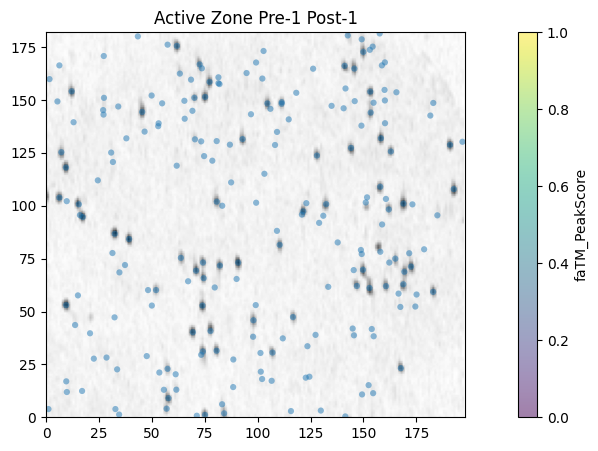

In [22]:
plt.figure(figsize=(30, 5))
plt.subplot(1, 2, 1)
plt.title('Active Zone Pre-1 Post-1')
plt.imshow(np.min(transformed_tomo['rendered_zonograms']['active_zone_pre1_post1']['transformed_tomogram'], axis=0), cmap='gray',origin='lower')
plt.scatter(
    transformed_coordinates[:, 0],
    transformed_coordinates[:, 1],
    #c=transformed_coordinates[:, 3], # color by peak score
    s=20,                # circle size
    edgecolors='none',       # red edge
    alpha=0.5,             # transparency
    cmap='rainbow',         # colormap
)
plt.xlim(0, transformed_tomo['rendered_zonograms']['active_zone_pre1_post1']['transformed_tomogram'].shape[2])
plt.ylim(0, transformed_tomo['rendered_zonograms']['active_zone_pre1_post1']['transformed_tomogram'].shape[1])
plt.colorbar(label='faTM_PeakScore')

In [14]:
from torch_find_peaks.refine_peaks import refine_peaks_3d
import mrcfile

In [15]:
mrcs = list((Path(tomo_path) / 'best_alignment').glob(f'*BP_3DCTF_BIN4.mrc'))
print(mrcs)
with mrcfile.open(mrcs[0], 'r') as mrc:
    tomo_data = torch.tensor(mrc.data).to("cuda:0")

[PosixPath('/goliath/processing/Gouaux/CJS/BestTomo/ProcessingCJS/tomograms/15F1/TOP_TOMOS/20230512-EG18pos2_80/best_alignment/20230512-EG18pos2_80_full_rec_BP_3DCTF_BIN4.mrc')]


In [39]:
peak_data = torch.tensor(star_data[['faTM_PeakZ', 'faTM_PeakY', 'faTM_PeakX']].values,dtype=torch.float32).to("cuda:0")
refined_peak_data = refine_peaks_3d(
    volume = -1. * tomo_data,
    peak_coords= peak_data,
    return_as="diagnostic",
    boxsize=8,
    learning_rate=0.001,
    center_regularization=0.01,
    amplitude_consistency= 0.000000,
    sigma_consistency= 0.000000,
    background_consistency=0.000000,
    max_iterations=1000
)
# Get index of max in boxes
rdp = refined_peak_data['refined_peaks']
rdp["integral"] = rdp["amplitude"] * rdp["sigma_x"] * rdp["sigma_y"] * rdp["sigma_z"]
#Make index a column
rdp = rdp.reset_index()
rdp = rdp[rdp['amplitude'] > 0.85]
#rdp = rdp[rdp['integral'] > 0.02]
coordinates = rdp[['x', 'y', 'z']].values
transformed_coordinates = transform_coordinates_to_active_zonogram(coordinates, active_zonograms['zonogram_data']['active_zone_pre1_post1'])

Updates to peak coordinates (z,y,x): 0 -2 -1
Iter 0: 0.18937766551971436 min: 0.01343466155230999 max: 4.290236473083496
Iter 1: 0.18852916359901428 min: 0.013212664052844048 max: 4.285322189331055
Iter 2: 0.18768279254436493 min: 0.012992757372558117 max: 4.280406951904297
Iter 3: 0.18683862686157227 min: 0.012774979695677757 max: 4.275490760803223
Iter 4: 0.18599668145179749 min: 0.012559364549815655 max: 4.270575046539307
Iter 5: 0.18515697121620178 min: 0.012345944531261921 max: 4.265658378601074
Iter 6: 0.18431958556175232 min: 0.012134751304984093 max: 4.260741710662842
Iter 7: 0.1834844946861267 min: 0.011925813741981983 max: 4.255824565887451
Iter 8: 0.18265177309513092 min: 0.011719164438545704 max: 4.250906944274902
Iter 9: 0.18182148039340973 min: 0.01151482854038477 max: 4.245988368988037
Iter 10: 0.18099358677864075 min: 0.011312833987176418 max: 4.241069793701172
Iter 11: 0.18016815185546875 min: 0.011113201268017292 max: 4.23615026473999
Iter 12: 0.17934520542621613 min:

In [32]:
rdp.sort_values('amplitude', ascending=False)

,index,amplitude,z,y,x,sigma_x,sigma_y,sigma_z,background,loss,integral
1955,1955,3.670556,108.760910,731.550232,643.044434,2.343912,2.849118,2.953760,-1.118684,0.382372,72.403343
614,614,3.257082,111.896179,731.104614,643.043701,2.534381,2.730409,2.861716,-1.015535,0.312525,64.499290
3,3,3.008125,73.699005,1144.031616,352.929077,1.571830,2.155333,2.634827,-0.654663,0.149795,26.851471
2,2,2.990822,134.917160,1008.279724,822.010864,1.449815,2.137939,2.655851,-0.605620,0.158923,24.620808
0,0,2.779510,94.859787,457.248474,648.911926,0.986803,1.673464,2.291479,-0.391032,0.104716,10.517941
...,...,...,...,...,...,...,...,...,...,...,...
89,89,1.040649,38.887863,636.067749,183.075485,0.722029,1.462095,1.911440,-0.091842,0.034206,2.099883
44,44,1.036015,275.900055,621.350525,476.811829,0.798693,1.307389,1.960820,-0.074699,0.028770,2.121232
259,259,1.015929,189.885239,681.063660,404.760956,0.886336,1.590370,2.044023,-0.136716,0.036267,2.927155
1726,1726,1.010065,317.910461,89.877640,523.692444,0.794193,1.368365,1.972385,-0.104563,0.031017,2.165054


In [33]:
paste_into = np.zeros_like(tomo_data.cpu().numpy())
for i in range(refined_peak_data['output'].shape[0]):
    x, y, z = refined_peak_data['refined_peaks'].iloc[i][['x', 'y', 'z']].astype(int)
    paste_into[z-4:z+4, y-4:y+4, x-4:x+4] = refined_peak_data['output'][i].detach().cpu().numpy()
transformed_ino = extract_active_zonogram(active_zonograms=active_zonograms, active_zones=active_zones_glb, tomo_path=paste_into)
plt.imshow(np.min(-transformed_ino['rendered_zonograms']['active_zone_pre1_post1']['transformed_tomogram'], axis=0), cmap='gray',origin='lower')


Rendering active zonogram


TypeError: expected str, bytes or os.PathLike object, not ndarray

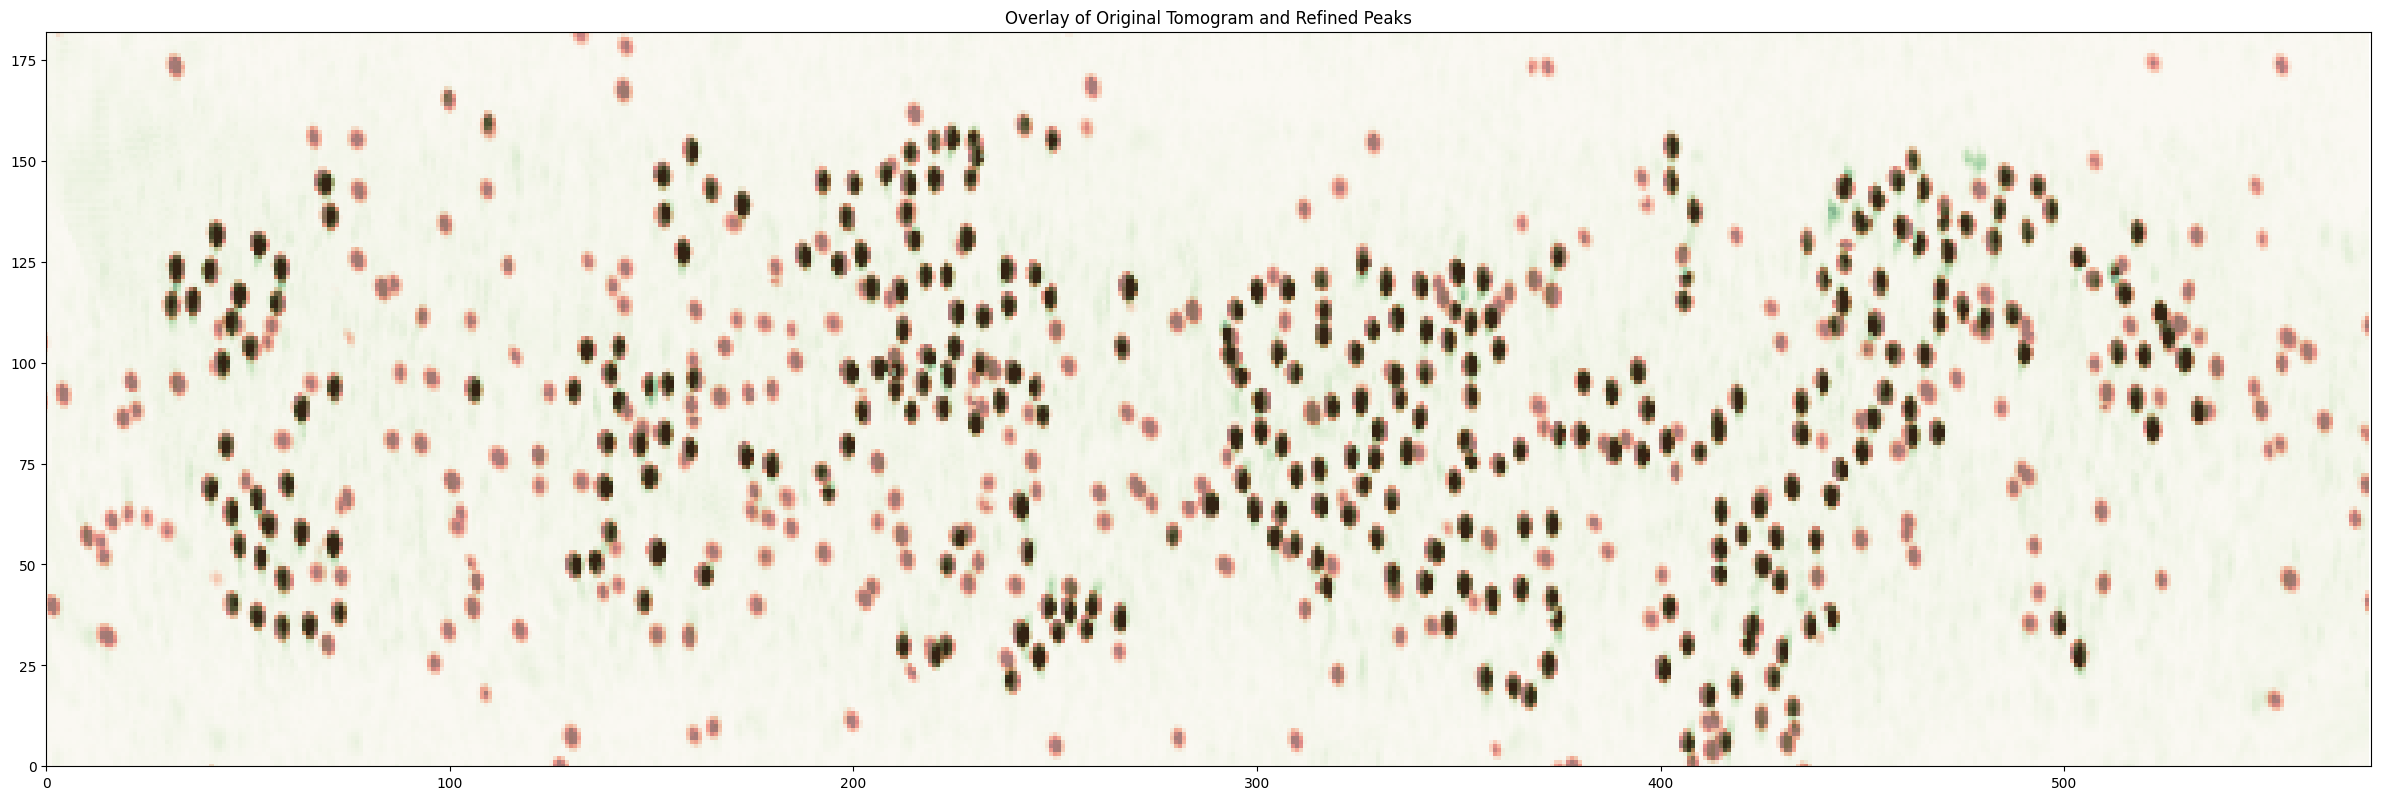

In [58]:
plt.figure(figsize=(30, 10))
plt.title('Overlay of Original Tomogram and Refined Peaks')
plt.imshow(-np.min(transformed_tomo['rendered_zonograms']['active_zone_pre1_post1']['transformed_tomogram'], axis=0), cmap='Greens', origin='lower', alpha=1,vmin=0.01,vmax=0.4)
plt.imshow(-np.min(-transformed_ino['rendered_zonograms']['active_zone_pre1_post1']['transformed_tomogram'], axis=0), cmap='Reds', origin='lower', alpha=0.5,vmin=0.01,vmax=0.4)
plt.xlim(0, transformed_tomo['rendered_zonograms']['active_zone_pre1_post1']['transformed_tomogram'].shape[2])
plt.ylim(0, transformed_tomo['rendered_zonograms']['active_zone_pre1_post1']['transformed_tomogram'].shape[1])
plt.show()

/tmp/ipykernel_1303035/3655751366.py:5: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  plt.scatter(


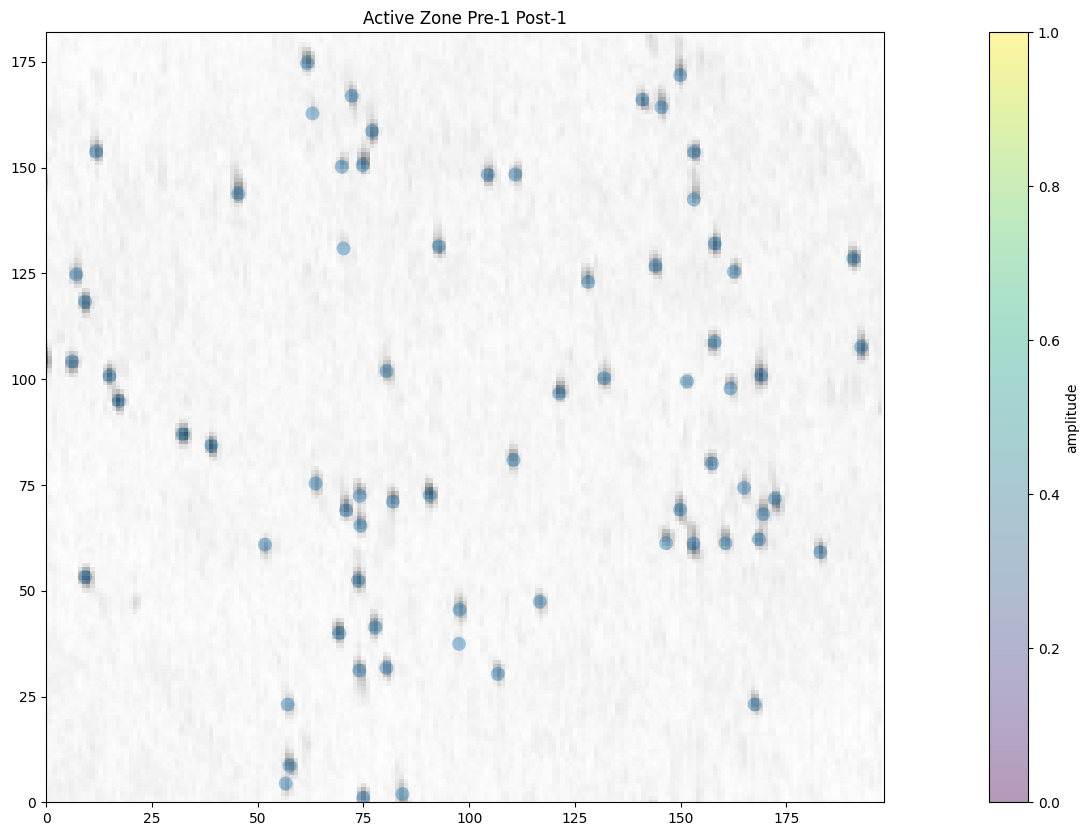

In [40]:
plt.figure(figsize=(60, 10))
plt.subplot(1, 2, 1)
plt.title('Active Zone Pre-1 Post-1')
plt.imshow(np.min(transformed_tomo['rendered_zonograms']['active_zone_pre1_post1']['transformed_tomogram'], axis=0), cmap='gray',origin='lower',vmin=-0.6)
plt.scatter(
    transformed_coordinates[:, 0],
    transformed_coordinates[:, 1],
    #c=transformed_coordinates[:, 3]>1.3, # color by integral
    s=100,                # circle size
    edgecolors='none',       # red edge
    alpha=0.4,             # transparency
    cmap='rainbow',         # colormap
)
plt.xlim(0, transformed_tomo['rendered_zonograms']['active_zone_pre1_post1']['transformed_tomogram'].shape[2])
plt.ylim(0, transformed_tomo['rendered_zonograms']['active_zone_pre1_post1']['transformed_tomogram'].shape[1])
plt.colorbar(label='amplitude')
plt.show()

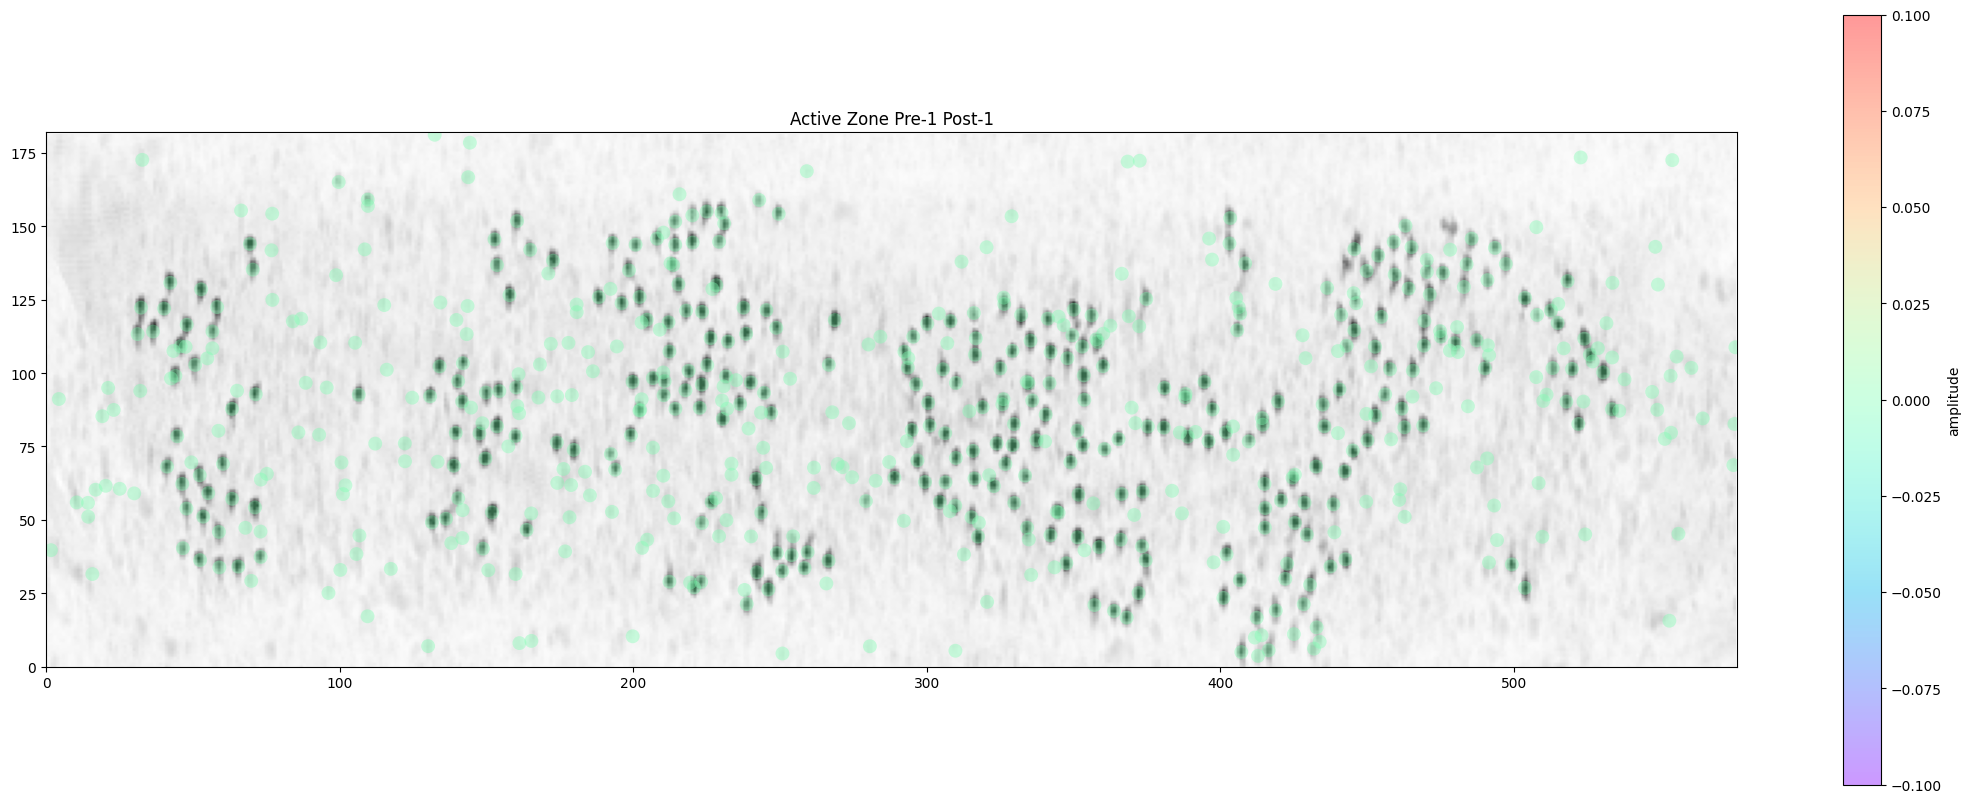

In [76]:
plt.figure(figsize=(60, 10))
plt.subplot(1, 2, 1)
plt.title('Active Zone Pre-1 Post-1')
plt.imshow(np.min(transformed_tomo['rendered_zonograms']['active_zone_pre1_post1']['transformed_tomogram'], axis=0), cmap='gray',origin='lower',vmin=-0.6)
plt.scatter(
    transformed_coordinates[:, 0],
    transformed_coordinates[:, 1],
    c=transformed_coordinates[:, 4]>1.5, # color by integral
    s=100,                # circle size
    edgecolors='none',       # red edge
    alpha=0.4,             # transparency
    cmap='rainbow',         # colormap
)
plt.xlim(0, transformed_tomo['rendered_zonograms']['active_zone_pre1_post1']['transformed_tomogram'].shape[2])
plt.ylim(0, transformed_tomo['rendered_zonograms']['active_zone_pre1_post1']['transformed_tomogram'].shape[1])
plt.colorbar(label='amplitude')
plt.show()

<Axes: >

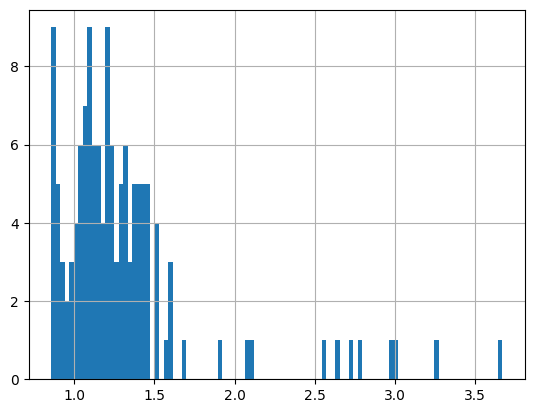

In [41]:
rdp["amplitude"].hist(bins=100)

<Axes: >

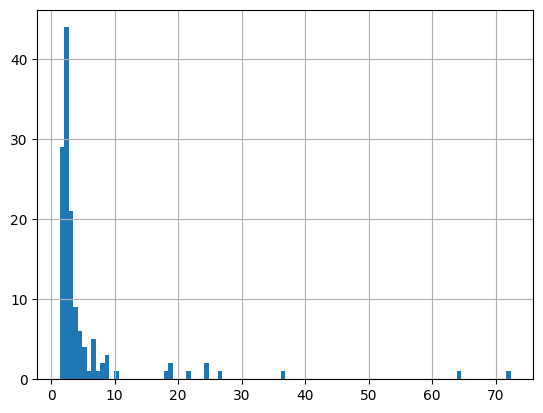

In [42]:
rdp["integral"].hist(bins=100)

<Axes: >

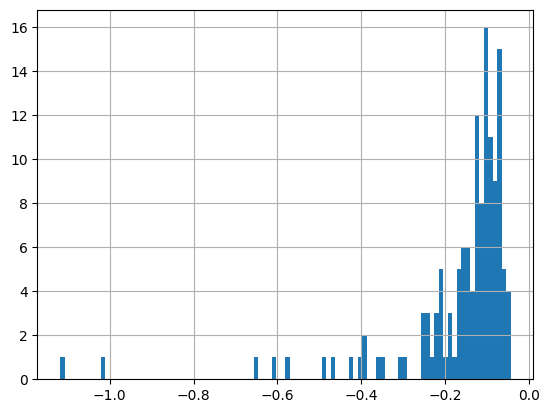

In [43]:
rdp["background"].hist(bins=100)

<Axes: >

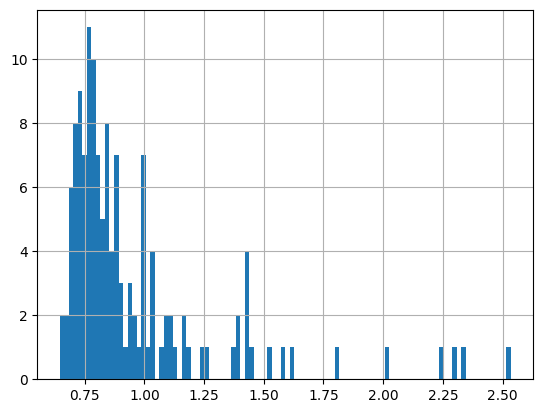

In [44]:
rdp["sigma_x"].hist(bins=100)

<Axes: >

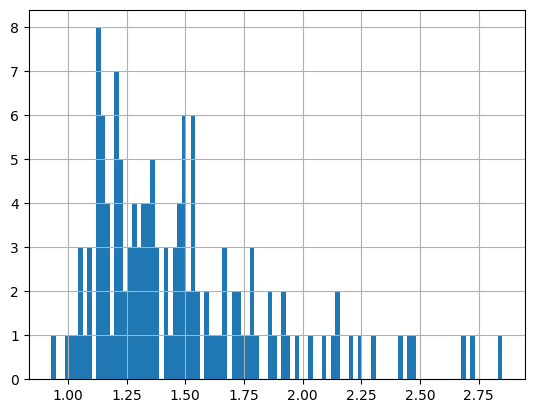

In [45]:
rdp["sigma_y"].hist(bins=100)

<Axes: >

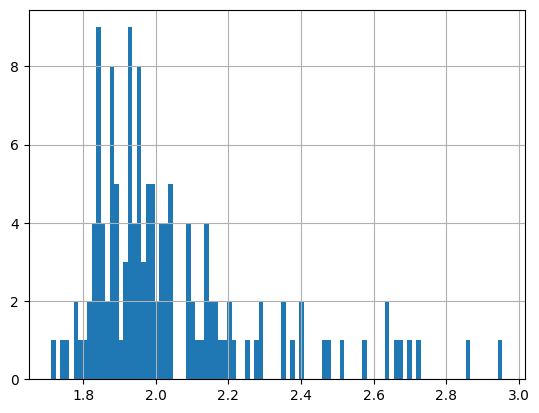

In [46]:
rdp["sigma_z"].hist(bins=100)